In [11]:
import pandas as pd 

df = pd.read_csv("../data/raw/spam.csv", encoding = "latin-1")

In [12]:
df = df.rename(columns={"v1": "message_type", "v2": "message"})

print(df.shape)
print(df.info())

(5572, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   message_type  5572 non-null   object
 1   message       5572 non-null   object
 2   Unnamed: 2    50 non-null     object
 3   Unnamed: 3    12 non-null     object
 4   Unnamed: 4    6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB
None


In [43]:
extra = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

df["message"] = df[["message"] + extra].apply(
    lambda row: ",".join(row.dropna()), axis = 1
)
df = df.drop(columns=extra)

In [ ]:
df.duplicated("message").sum()


403

message_type
ham     0.865937
spam    0.134063
Name: proportion, dtype: float64


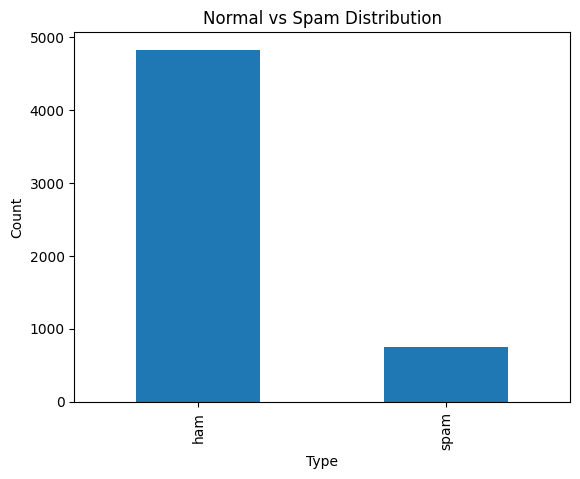

In [49]:
import matplotlib.pyplot as plt
print(df.message_type.value_counts(normalize=True))
df.message_type.value_counts().plot(kind = "bar")
plt.title("Normal vs Spam Distribution")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

Basic Stats of Messages

In [23]:
df["message_length"] = df.message.apply(len)
print(df["message_length"].describe())

count    5572.000000
mean       80.118808
std        59.690841
min         2.000000
25%        36.000000
50%        61.000000
75%       121.000000
max       910.000000
Name: message_length, dtype: float64


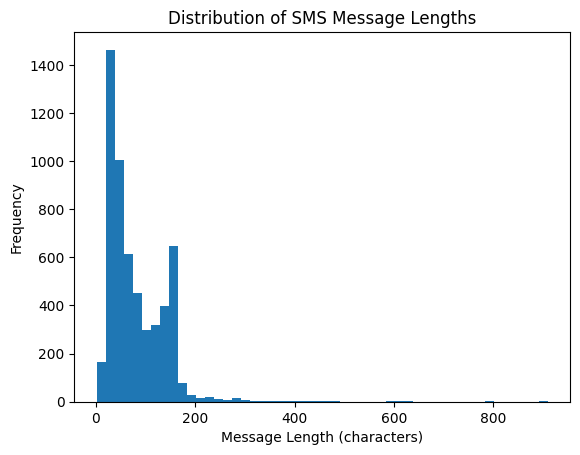

In [24]:
plt.hist(df["message_length"], bins=50)

plt.title("Distribution of SMS Message Lengths")
plt.xlabel("Message Length (characters)")
plt.ylabel("Frequency")

plt.show()

Compare Spam vs Ham

In [27]:
print(df["message_length"].groupby(df["message_type"]).describe())

               count        mean        std   min    25%    50%    75%    max
message_type                                                                 
ham           4825.0   71.023627  58.016023   2.0   33.0   52.0   92.0  910.0
spam           747.0  138.866131  29.183082  13.0  132.5  149.0  157.0  224.0


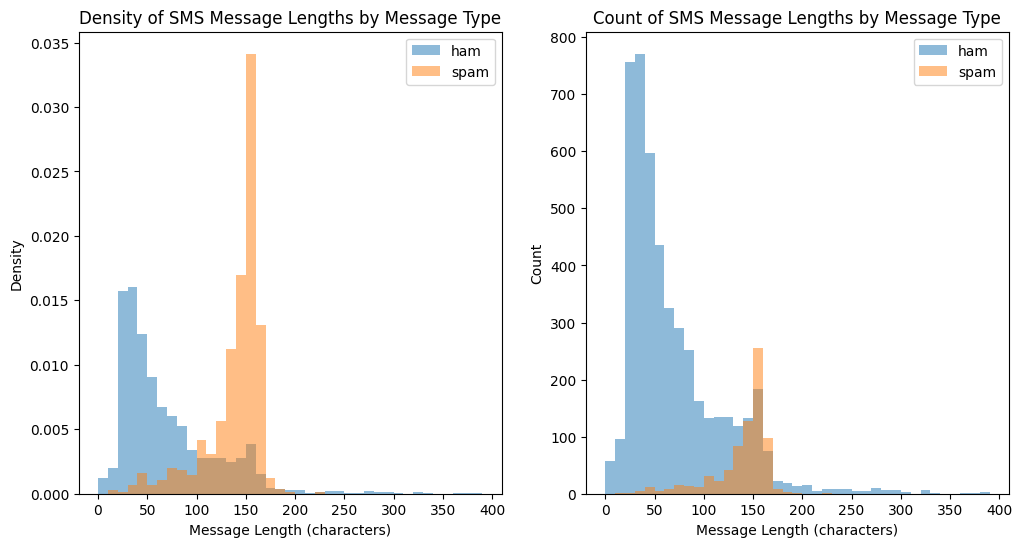

In [57]:
bins = range(0, 400, 10)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 6))

for label in ["ham", "spam"]:
    axes[0].hist(
        df.loc[df["message_type"] == label, "message_length"],
        bins=bins,
        alpha=0.5,
        density=True,
        label=label
    )
    axes[1].hist(
        df.loc[df["message_type"] == label, "message_length"],
        bins=bins,
        alpha=0.5,
        density=False,
        label=label
    )
axes[0].set_title("Density of SMS Message Lengths by Message Type")
axes[1].set_title("Count of SMS Message Lengths by Message Type")
axes[0].set_xlabel("Message Length (characters)")
axes[1].set_xlabel("Message Length (characters)")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Count")
axes[0].legend()
axes[1].legend()
plt.show()

In [58]:
pd.crosstab(df.message_type, df.message_length > 120)

message_length,False,True
message_type,,
ham,4024,801
spam,135,612
